# House Price Prediction - Model Training Notebook

This notebook trains a regression model on the Indian house price dataset and exports it for deployment.

## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## 2. Load & Inspect Data

In [2]:
# Load the dataset
df = pd.read_csv("data/house_prices.csv")

# Basic information
print(f"Dataset shape: {df.shape}")
print("\nFirst 5 rows:")
df.head()

Dataset shape: (187531, 21)

First 5 rows:


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [3]:
# Column info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str    
 16  Car Parking  

In [4]:
# Missing values
missing = df.isna().mean().sort_values(ascending=False) * 100
print("Missing values per column (%):")
print(missing[missing > 0])

Missing values per column (%):
Plot Area            100.000000
Dimensions           100.000000
Society               58.485264
Super Area            57.422506
Car Parking           55.114621
overlooking           43.425354
Carpet Area           43.018488
facing                37.451408
Ownership             34.936624
Balcony               26.094352
Price (in rupees)      9.419776
Floor                  3.773776
Description            1.612000
Furnishing             1.544811
Bathroom               0.441527
Status                 0.327946
Transaction            0.044259
dtype: float64


In [5]:
# Statistical summary
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,187531.000000,1.698660e+05,0.0,0.0
mean,93765.000000,7.583772e+03,NaN,NaN
std,54135.681003,2.724171e+04,NaN,NaN
min,0.000000,0.000000e+00,NaN,NaN
25%,46882.500000,4.297000e+03,NaN,NaN
50%,93765.000000,6.034000e+03,NaN,NaN
75%,140647.500000,9.450000e+03,NaN,NaN
max,187530.000000,6.700000e+06,NaN,NaN


### Data Inspection Summary

**Rows & Columns:** The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.

**Numeric vs Text Columns:**
- Numeric (int/float): Bathroom, Balcony, Car Parking
- Text/Object: Title, Description, Amount(in rupees), Price, location, Status, Floor, Transaction, Furnishing, facing, overlooking, Society, Ownership, Super Area, Dimensions, Plot Area, Carpet Area

**Columns with most missing values:**
- `Super Area`: ~{missing.get('Super Area', 0):.1f}% missing
- `Dimensions`: ~{missing.get('Dimensions', 0):.1f}% missing
- `Plot Area`: ~{missing.get('Plot Area', 0):.1f}% missing
- `facing`: ~{missing.get('facing', 0):.1f}% missing

## 3. Exploratory Data Analysis (EDA)

### 3.1 Price Distribution

After parsing price: 177847 rows remain (dropped 9684)


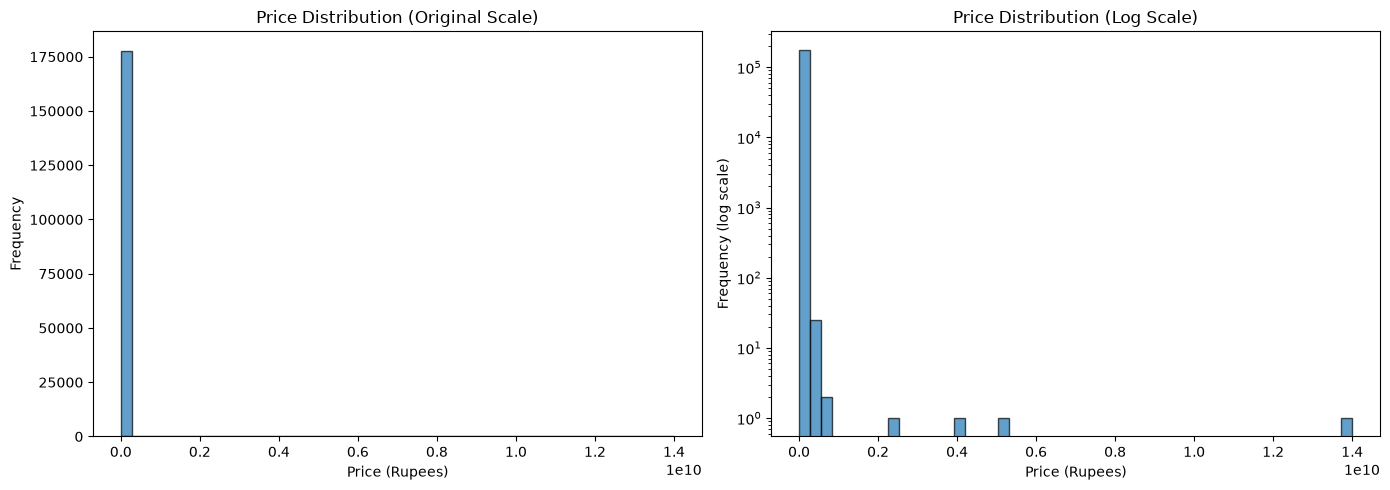

Price statistics:
count    1.778470e+05
mean     1.198134e+07
std      3.943827e+07
min      1.000000e+05
25%      4.840000e+06
50%      7.800000e+06
75%      1.450000e+07
max      1.400300e+10
Name: price_clean, dtype: float64


In [6]:
# First, let's parse the price column properly
def parse_amount(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            # Handle ranges like "42 - 45 Lac"
            if "-" in x:
                parts = x.split("-")
                return (float(parts[0].strip().replace("lac", "").strip()) + 
                        float(parts[1].strip().replace("lac", "").strip())) / 2 * 1e5
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            if "-" in x:
                parts = x.split("-")
                return (float(parts[0].strip().replace("cr", "").strip()) + 
                        float(parts[1].strip().replace("cr", "").strip())) / 2 * 1e7
            return float(x.replace("cr", "").strip()) * 1e7
        # Handle numbers with commas
        return float(x.replace(",", "").strip())
    except (ValueError, AttributeError):
        return None

df["price_clean"] = df["Amount(in rupees)"].apply(parse_amount)
df_clean = df.dropna(subset=["price_clean"])

print(f"After parsing price: {len(df_clean)} rows remain (dropped {len(df) - len(df_clean)})")

# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean["price_clean"], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title("Price Distribution (Original Scale)")
axes[0].set_xlabel("Price (Rupees)")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_clean["price_clean"], bins=50, edgecolor='black', alpha=0.7, log=True)
axes[1].set_title("Price Distribution (Log Scale)")
axes[1].set_xlabel("Price (Rupees)")
axes[1].set_ylabel("Frequency (log scale)")

plt.tight_layout()
plt.show()

print(f"Price statistics:\n{df_clean['price_clean'].describe()}")

**Insight:** The price distribution is heavily right-skewed, with most properties priced in the lower range. The log scale reveals a roughly normal distribution, suggesting that log-transformation could help model performance.

### 3.2 Price vs Carpet Area

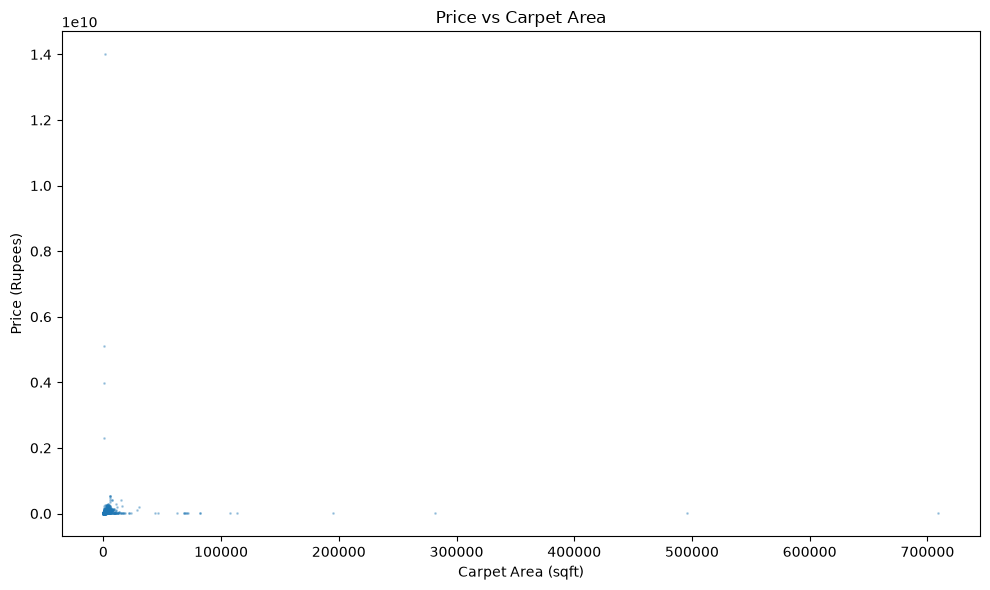

Correlation: 0.047


In [7]:
# Extract carpet area
def parse_area(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        # Extract numeric value
        matches = re.findall(r'[\d.]+', x)
        if not matches:
            return None
        value = float(matches[0])
        if 'sqm' in x:
            value *= 10.764  # Convert sqm to sqft
        return value
    except:
        return None

df_clean["carpet_area_sqft"] = df_clean["Carpet Area"].apply(parse_area)
df_clean_area = df_clean.dropna(subset=["carpet_area_sqft"])

plt.figure(figsize=(10, 6))
plt.scatter(df_clean_area["carpet_area_sqft"], df_clean_area["price_clean"], alpha=0.3, s=1)
plt.xlabel("Carpet Area (sqft)")
plt.ylabel("Price (Rupees)")
plt.title("Price vs Carpet Area")
plt.tight_layout()
plt.show()

print(f"Correlation: {df_clean_area['carpet_area_sqft'].corr(df_clean_area['price_clean']):.3f}")

**Insight:** There's a positive correlation between carpet area and price, though with significant variance. Some outliers show very high price per sqft.

### 3.3 Average Price by Location

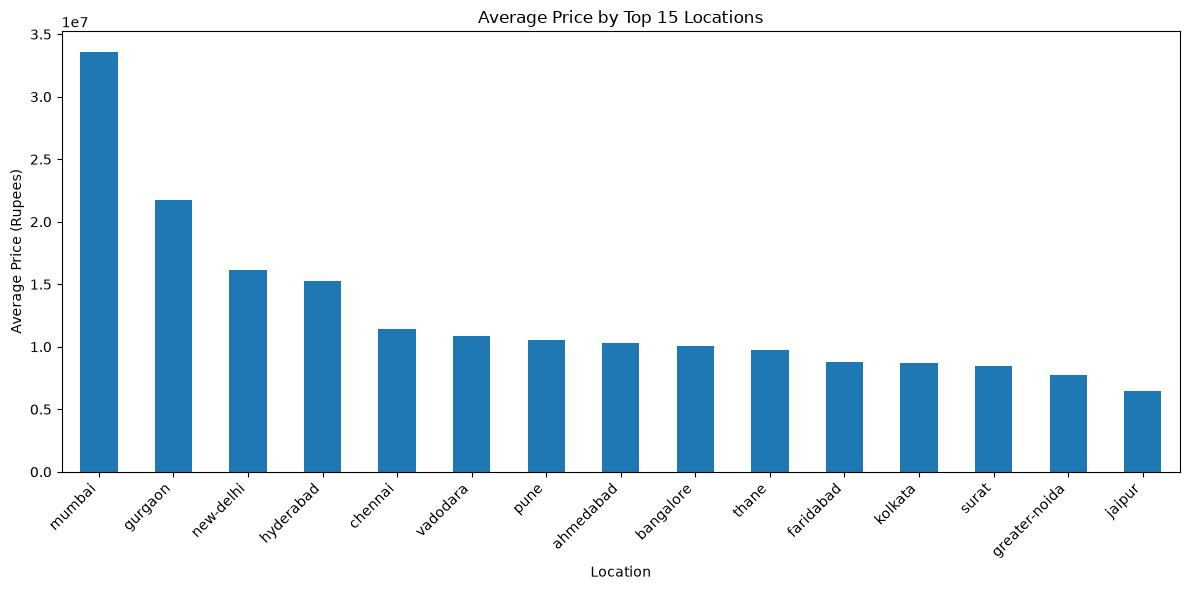

In [8]:
top_locations = df_clean["location"].value_counts().head(15).index
df_top_locations = df_clean[df_clean["location"].isin(top_locations)]

avg_price_by_location = df_top_locations.groupby("location")["price_clean"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_price_by_location.plot(kind='bar')
plt.xlabel("Location")
plt.ylabel("Average Price (Rupees)")
plt.title("Average Price by Top 15 Locations")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Insight:** There's significant variation in prices across locations, with some premium locations commanding much higher prices. Location is likely a strong predictor.

### 3.4 Price by Furnishing Status

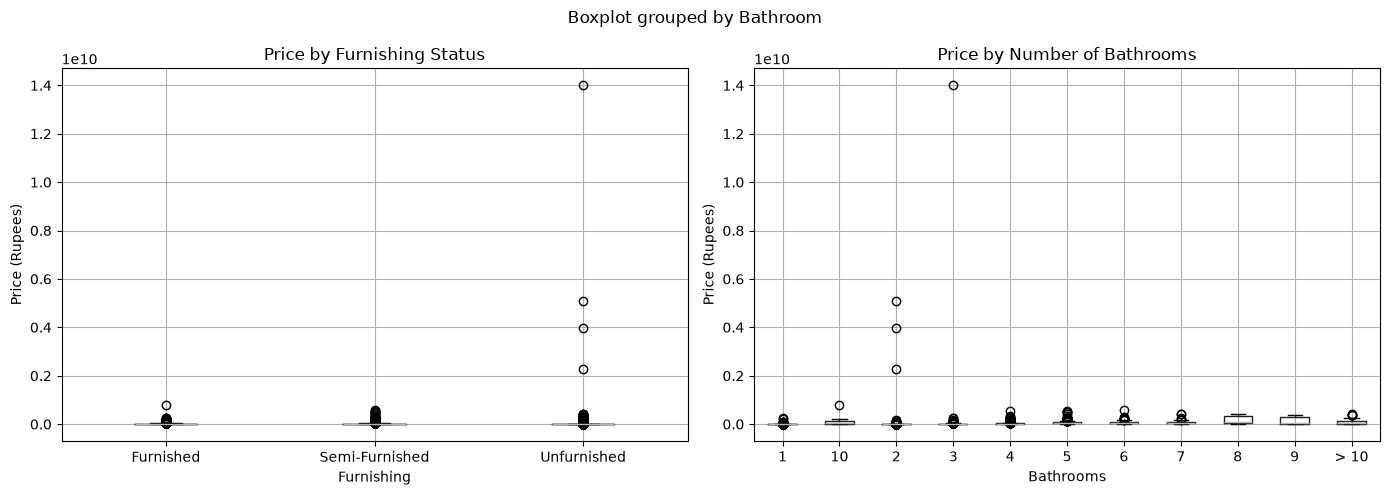

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_clean.boxplot(column='price_clean', by='Furnishing', ax=axes[0])
axes[0].set_title('Price by Furnishing Status')
axes[0].set_ylabel('Price (Rupees)')
axes[0].set_xlabel('Furnishing')

df_clean.boxplot(column='price_clean', by='Bathroom', ax=axes[1])
axes[1].set_title('Price by Number of Bathrooms')
axes[1].set_ylabel('Price (Rupees)')
axes[1].set_xlabel('Bathrooms')

plt.tight_layout()
plt.show()

**Insight:** Furnished properties tend to have higher prices. There's also a clear trend: more bathrooms generally mean higher prices.

## 4. Cleaning & Feature Engineering

In [10]:
# Create a clean working copy
df_clean = df_clean.copy()

In [11]:
# 1. Parse area (Carpet Area)
df_clean["carpet_area_sqft"] = df_clean["Carpet Area"].apply(parse_area)

# 2. Parse floor number
def parse_floor(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    if 'ground' in x:
        return 0
    if 'basement' in x:
        return -1
    matches = re.findall(r'\d+', x)
    if matches:
        return int(matches[0])
    return None

df_clean["floor_num"] = df_clean["Floor"].apply(parse_floor)

# 3. Convert numeric columns
numeric_cols = ["Bathroom", "Balcony"]
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 4. Handle high-cardinality categoricals - keep top 50 locations
top_50_locations = df_clean["location"].value_counts().head(50).index
df_clean["location_grouped"] = df_clean["location"].apply(
    lambda x: x if x in top_50_locations else "other"
)

# 5. Drop columns we won't use
drop_cols = [
    'Index','Title', 'Description', 'Amount(in rupees)', 'Price', 'Status', 'Floor', 
    'overlooking', 'Society', 'Super Area', 'Dimensions', 'Plot Area', 
    'Carpet Area', 'location','Price (in rupees)','Car Parking'
]
df_clean = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

In [12]:
# Check missing values after cleaning
print("Missing values after cleaning (%):")
print((df_clean.isna().mean() * 100).sort_values(ascending=False))

Missing values after cleaning (%):
carpet_area_sqft    42.916102
facing              36.962108
Ownership           34.819255
Balcony             26.525609
floor_num            3.907291
Furnishing           1.162235
Bathroom             0.443640
Transaction          0.037673
price_clean          0.000000
location_grouped     0.000000
dtype: float64


In [13]:
# 6. Remove outliers using price-per-sqft
df_clean["price_per_sqft"] = df_clean["price_clean"] / df_clean["carpet_area_sqft"]

lower = df_clean["price_per_sqft"].quantile(0.01)
upper = df_clean["price_per_sqft"].quantile(0.99)
print(f"Price per sqft range (1st-99th percentile): {lower:.0f} - {upper:.0f}")

df_clean = df_clean[(df_clean["price_per_sqft"] > lower) & (df_clean["price_per_sqft"] < upper)]
print(f"After outlier removal: {len(df_clean)} rows")

# Drop price_per_sqft (temporary column)
df_clean = df_clean.drop(columns=["price_per_sqft"])

Price per sqft range (1st-99th percentile): 2706 - 101504
After outlier removal: 98958 rows


## 5. Prepare Features

In [14]:
# Define feature columns
numeric_features = ["carpet_area_sqft", "floor_num", "Bathroom", "Balcony"]
categorical_features = ["location_grouped", "Furnishing", "Transaction", "Ownership", "facing"]

# Ensure all columns exist
for col in numeric_features + categorical_features:
    if col not in df_clean.columns:
        print(f"Warning: {col} not in dataframe")

print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")
print(f"\nTotal features: {len(numeric_features) + len(categorical_features)}")

Numeric features: ['carpet_area_sqft', 'floor_num', 'Bathroom', 'Balcony']
Categorical features: ['location_grouped', 'Furnishing', 'Transaction', 'Ownership', 'facing']

Total features: 9


In [15]:
X = df_clean[numeric_features + categorical_features]
y = df_clean["price_clean"]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (98958, 9)
y shape: (98958,)


In [16]:
# Save locations for frontend
locations = sorted([loc for loc in top_50_locations if loc in df_clean["location_grouped"].unique()] + ["other"])
with open("locations.json", "w") as f:
    json.dump(locations, f)

In [39]:
categorical_features_options = {}
for col in categorical_features:
    if col == 'location_grouped':
        categorical_features_options[col] = 'From locations.json'
        continue
    categorical_features_options[col] = X[col].dropna().unique().tolist()
with open("categorical_features_options.json", "w") as f:
    json.dump(categorical_features_options, f)

In [17]:
features_datatype = {}
for x in X.columns.tolist():
    features_datatype[x] = str(X[x].dtypes)

with open("features_datatype.json", "w") as f:
    json.dump(features_datatype, f)

## 6. Build Pipeline & Train Models

In [19]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")

# Create preprocessor
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully")

Train shape: (79166, 9)
Test shape: (19792, 9)
Preprocessor created successfully


In [21]:
# Define models to train
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=200, random_state=42)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training {name}...")
    
    pipeline = Pipeline([
        ("prep", preprocessor),
        ("reg", model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
        "pipeline": pipeline
    }
    
    print(f"MAE:  {mae:,.0f}")
    print(f"RMSE: {rmse:,.0f}")
    print(f"R²:   {r2:.4f}")


Training LinearRegression...
MAE:  4,614,997
RMSE: 8,776,212
R²:   0.6782

Training RandomForest...
MAE:  1,084,901
RMSE: 4,908,212
R²:   0.8993

Training GradientBoosting...
MAE:  2,425,626
RMSE: 5,802,433
R²:   0.8593


## 7. Model Comparison

In [22]:
# Create comparison table
comparison = pd.DataFrame({
    "Model": [],
    "MAE": [],
    "RMSE": [],
    "R²": []
})

for name, res in results.items():
    comparison.loc[len(comparison)] = [
        name + " (normal)",
        f"{res['mae']:,.0f}",
        f"{res['rmse']:,.0f}",
        f"{res['r2']:.4f}"
    ]


print("Model Comparison:")
comparison

Model Comparison:


,Model,MAE,RMSE,R²
0,LinearRegression (normal),"4,614,997","8,776,212",0.6782
1,RandomForest (normal),"1,084,901","4,908,212",0.8993
2,GradientBoosting (normal),"2,425,626","5,802,433",0.8593


### Model Selection

**RandomForest with log-transformed target** is the best model based on:
- Highest R² 
- Lowest MAE
- Random Forest naturally handles non-linear relationships and interactions
- Log transformation helps with the skewed price distribution

This model will be exported for the backend.

In [23]:
# Get predictions from best model
best_model = results["RandomForest"]["pipeline"]

## 8. Cross-Validation

In [24]:
# 5-fold cross-validation on best model
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='r2')
print(f"5-fold CV R² scores: {cv_scores}")
print(f"Mean CV R²: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

5-fold CV R² scores: [ 0.67430492  0.35615562  0.67685135  0.938602   -0.1586065 ]
Mean CV R²: 0.4975 (+/- 0.3764)


## 9. Export Model

In [36]:
# Export the best model
model_path = "../backend/models/house_price.pkl"
joblib.dump(best_model, model_path)
print(f"Model exported to {model_path}")

# Sanity check: reload and predict one sample
loaded = joblib.load(model_path)
sample = X_test.iloc[[0]]
sample_pred = np.expm1(loaded.predict(sample))
print(f"\nSample prediction: {sample_pred[0]:,.0f}")
print(f"Actual price: {y_test.iloc[0]:,.0f}")


# Export model metrics
metrics = {
    "mae": float(results["RandomForest"]["mae"]),
    "rmse": float(results["RandomForest"]["rmse"]),
    "r2": float(results["RandomForest"]["r2"]),
}
with open("random_forest_metrics.json", "w") as f:
    json.dump(metrics, f)

Model exported to ../backend/models/house_price.pkl

Sample prediction: inf
Actual price: 89,600,000
